# This is the *T4 & T6* Section

In [10]:
#import libraries needed for T4 and T
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [11]:
#load csv
df = pd.read_csv("iris_data.csv")
display(df.head())
print("Dataset shape:", df.shape)
df.info()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [12]:
#select target features 
df_binary = df[df["target"].isin([0, 1])].copy()
print("Binary classification dataset:")
print("Number of samples:", len(df_binary))
print("\nClass distribution:")
print(df_binary["target"].value_counts())

Binary classification dataset:
Number of samples: 100

Class distribution:
target
0    50
1    50
Name: count, dtype: int64


In [13]:
#separate x and y features
X = df_binary.drop("target", axis=1)
y = df_binary["target"]
print("Features:")
print(X.columns.tolist())
print("\nTarget:")
print(y.name)

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target:
target


In [14]:
#split for train/test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 80
Testing samples : 20


In [15]:
#apply logistic regression model
model = LogisticRegression(
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("logistic regression model trained")

logistic regression model trained


In [16]:
#logistic regression coefficients
print("Logistic Regression Coefficients")
print(f"Intercept (b0): {model.intercept_[0]:.6f}")
for feature, coefficient in zip(X.columns, model.coef_[0]):
    print(f"{feature} coefficient: {coefficient:.6f}")

#logistic regression equation
equation = f"z = {model.intercept_[0]:.4f}"
for feature, coefficient in zip(X.columns, model.coef_[0]):
    sign = "+" if coefficient >= 0 else "-"
    equation += f" {sign} {abs(coefficient):.4f}({feature})"
print(equation)

Logistic Regression Coefficients
Intercept (b0): -7.162805
sepal length (cm) coefficient: 0.537491
sepal width (cm) coefficient: -0.794302
petal length (cm) coefficient: 2.185114
petal width (cm) coefficient: 0.907145
z = -7.1628 + 0.5375(sepal length (cm)) - 0.7943(sepal width (cm)) + 2.1851(petal length (cm)) + 0.9071(petal width (cm))


# This is the *T4* Section

In [ ]:
#calculate performance metrics
accuracy = accuracy_score(y_test, y_pred) #(TP+TN)/(TP+TN+FP+FN)
precision = precision_score(y_test, y_pred) #(TP)/(TP+FP)
recall = recall_score(y_test, y_pred) #(TP)/(TP+FN)
f1 = f1_score(y_test, y_pred) #(2*prec*rec)/(prec+rec)
print("Logistic Regression Performance")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Logistic Regression Performance
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000


Confusion Matrix
[[10  0]
 [ 0 10]]


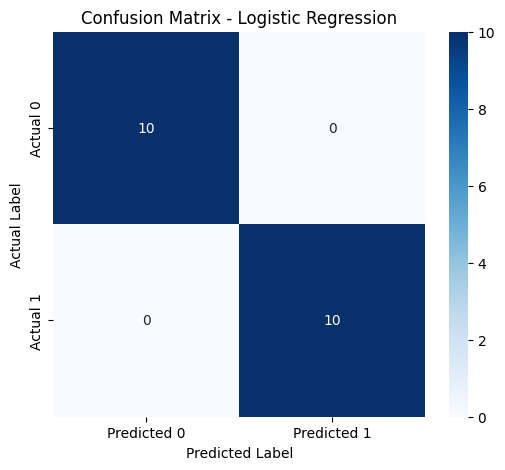

In [18]:
#confusion matrix for the logistic regression
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()
